In [56]:
import pandas as pd
from tqdm import tqdm
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import subprocess
from multiprocessing import Pool
import math 

In [57]:
accessions=['at6923', 'at6929', 'at7143', 'at8285', 'at9104', 'at9336', 'at9503', 'at9578', 'at9744', 'at9762', 'at9806', 'at9830', 'at9847', 'at9852', 'at9879', 'at9883', 'at9900']

In [53]:
def junctions_bed(acc):
#for j, c in zip(junctions, classifications):
    junc=pd.read_csv(f"output/{acc}/sqanti/{acc}-hodgepodgemerged_junctions.txt",sep="\t")
    classi=pd.read_csv(f"output/{acc}/sqanti/{acc}-hodgepodgemerged_classification.txt",sep="\t")
    classi=classi[['isoform','associated_gene']].drop_duplicates()
    junc=pd.merge(junc, classi, on="isoform")
        
    junc["feature"] = junc["isoform"] + "_" +junc["junction_number"].str.replace("_", ".")

    # replace true/false
    junc["bite_junction"] = junc["bite_junction"].astype(int)
    junc["RTS_junction"] = junc["RTS_junction"].astype(int)
    
    # drop unused columns
    junc=junc.drop(labels=['isoform','junction_number','transcript_coord', 
                           'indel_near_junct', 'phyloP_start', 'phyloP_end', 
                           'sample_with_cov', 'total_coverage_unique', 'total_coverage_multi'], axis=1)
    # reorder columns
    junc = junc[['chrom', 'genomic_start_coord', 'genomic_end_coord', 
                'strand', 'feature', 'associated_gene','junction_category', 'start_site_category', 
                'end_site_category', 'diff_to_Ref_start_site', 'diff_to_Ref_end_site', 
                'bite_junction', 'splice_site', 'canonical', 'RTS_junction']]
    
    if not os.path.exists(f"output/04/{acc}"):
        os.mkdir(f"output/04/{acc}")
    junc.to_csv(f"output/04/{acc}/{acc}-hodgepodgemerged_junctions.bed", sep="\t", index=False)

In [54]:
if __name__ == '__main__':
    with Pool(17) as p:
        print(p.map(junctions_bed, accessions))

[None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]


### TEST CASE

In [58]:
# load junctions file
at=pd.read_csv(f'output/at9900/sqanti/at9900-hodgepodgemerged_junctions.txt', sep="\t")
at["gene"]=at["isoform"].str.split(".").str[0]

# prepare read support
reads = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9900.collapsed.tama.v2_read_support.txt", sep="\t")
r_sub = reads[["merge_trans_id","trans_read_count"]]
r_sub.columns = ["isoform", "isoform_reads"]

# add read_support
merged_rs = pd.merge(left=at, right=r_sub, how='left', left_on='isoform', right_on='isoform')

# prepare sqanti (isoform-associated_gene)
#sqanti=pd.read_csv(f"/tmp/global2/lvaness/dl20-annex/final/isoseq/sqanti/at9900-hodgepodgemerged_classification.txt", sep="\t")
sqanti=pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/output/at9900/sqanti/at9900-hodgepodgemerged_classification.txt", sep="\t")


sqanti_sub=sqanti[["isoform","associated_gene"]]
span = 2
sqanti_sub["hodgepodge_gene"]=sqanti_sub["associated_gene"].transform(lambda x: ["_".join(x.split("_")[i:i+span]) for i in range(0, len(x.split("_")), span)])
#sqanti_sub["hodgepodge_gene_count"]=sqanti_sub["associated_gene"].transform(lambda x: ["_".join(x.split("_")[i:i+span]) for i in range(0, len(x.split("_")), span)]).str.len()
#sqanti_sub=sqanti_sub.loc[sqanti_sub["hodgepodge_gene_count"]>1]

# add associated hodgepodge gene
merged_rs_sqanti = pd.merge(left=merged_rs, right=sqanti_sub, how='left', left_on='isoform', right_on='isoform')

# prepare hodgepodge gff
columns=["chrom","source","feature","hodgepodge_genomic_start_coord","hodgepodge_genomic_end_coord","score","strand","frame","attribute"]
gff=pd.read_csv("/tmp/global2/lvaness/dl20-annex/final/annotation/latest/at9900_hodgepodgemerged.gff3", sep="\t", header=None, names=columns)
gff_genes=gff.loc[(gff["feature"]=="gene")|(gff["feature"]=="pseudogene")|(gff["feature"]=="pseudogenic_region")|(gff["feature"]=="transposable_element_gene")]
gff_genes["hodgepodge_gene"]=gff_genes["attribute"].str.split(";").str[0].str.split("=").str[1]
gff_genes_sub=gff_genes[["hodgepodge_gene","hodgepodge_genomic_start_coord","hodgepodge_genomic_end_coord"]]

# add gene coordinates
merged_rs_sqanti=merged_rs_sqanti.explode("hodgepodge_gene")
merged_rs_sqanti_coords=pd.merge(left=merged_rs_sqanti, right=gff_genes_sub, how='left', left_on='hodgepodge_gene', right_on='hodgepodge_gene')

# prepare gene type
nlr = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/input/ref_sets/new_ids/nlr_at9900.txt", sep="\t", names=["hodgepodge_gene"])
nlr["type"]="nlr"
busco = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/input/ref_sets/new_ids/busco_at9900.txt", sep="\t", names=["hodgepodge_gene"])
busco["type"]="busco"
house=pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/input/ref_sets/new_ids/housekeeping_at9900.txt", sep="\t", names=["hodgepodge_gene"])
house["type"]="house"
all_sets=pd.concat([nlr, busco, house])
all_sets

custom_dict = {'nlr':0, 'house':1, 'busco':2}  
all_sets['rank'] = all_sets['type'].map(custom_dict)
all_sets=all_sets.sort_values(by="rank").drop_duplicates(subset=["hodgepodge_gene"])

# add gene type
merged_all=pd.merge(left=merged_rs_sqanti_coords, right=all_sets, how='left', left_on='hodgepodge_gene', right_on='hodgepodge_gene')
merged_all["type"].fillna("other", inplace=True)

merged_all["junction_id"]=merged_all["chrom"] + ":" + merged_all["genomic_start_coord"].astype(str) + "-" + merged_all["genomic_end_coord"].astype(str)
merged_all_subs=merged_all[["chrom","isoform","gene","strand","junction_id","canonical","type","isoform_reads","genomic_start_coord","genomic_end_coord", "hodgepodge_gene","hodgepodge_genomic_start_coord","hodgepodge_genomic_end_coord"]]

In [ ]:
# per gene multiple donor-acceptor usage
all_genes=pd.DataFrame()
multi_usage=merged_all_subs.loc[merged_all_subs["hodgepodge_gene"].str.split("_").str[0]=="at9900"]
for gene in tqdm(multi_usage.groupby(by="hodgepodge_gene")):
    #print(gene[0])
    g_df=pd.DataFrame()
    g_df["hodgepodge_gene"]=[gene[0]]
    g_df["type"]=gene[1]["type"].unique()
    if gene[1]["strand"].unique()=="+":
        df=gene[1][["genomic_start_coord", "genomic_end_coord"]].drop_duplicates()
        comm_donor=0
        for donor in df.groupby(by="genomic_start_coord"):
            if len(donor[1]["genomic_end_coord"]) > 1:
                comm_donor +=1
        comm_acceptor=0
        for acceptor in df.groupby(by="genomic_end_coord"):
            if len(donor[1]["genomic_start_coord"]) > 1:
                comm_acceptor +=1        
        g_df["comm_donor"] = comm_donor
        g_df["comm_acceptor"] = comm_acceptor
    else:
        df=gene[1][["genomic_start_coord", "genomic_end_coord"]].drop_duplicates()
        comm_donor=0
        for donor in df.groupby(by="genomic_end_coord"):
            if len(donor[1]["genomic_start_coord"]) > 1:
                comm_donor +=1
        comm_acceptor=0
        for acceptor in df.groupby(by="genomic_start_coord"):
            if len(donor[1]["genomic_end_coord"]) > 1:
                comm_acceptor +=1
        g_df["comm_donor"] = comm_donor
        g_df["comm_acceptor"] = comm_acceptor
    all_genes=pd.concat([all_genes, g_df])

In [45]:
multi_usage["canonical"].value_counts()

canonical        1276586
non_canonical       2341
Name: canonical, dtype: int64

In [202]:
### per gene and per junction file
acc_df=pd.DataFrame()

for junc in tqdm(merged_all_subs.groupby(by="junction_id")):
    #print(junc[1])
    #print(junc[0])
    g_df=pd.DataFrame()
    if len(junc[1]["hodgepodge_gene"].unique())>1:
        #print(junc[1]["hodgepodge_gene"])
        for hodge in junc[1].groupby(by="hodgepodge_gene"):
            #print(hodge[0])
            #print("\n")
            j_df=pd.DataFrame()
            #get gene and strand
            j_df["chrom"]=[junc[1]["chrom"].unique()[0]]
            j_df["genomic_start_coord"]=junc[1]["genomic_start_coord"].unique()[0]
            j_df["genomic_end_coord"]=junc[1]["genomic_end_coord"].unique()[0]
            j_df["strand"]=junc[1]["strand"].unique()[0]
            j_df["junction_id"]=junc[1]["junction_id"].unique()[0]
            j_df["read_support"]=hodge[1]["isoform_reads"].sum()
            j_df["isoform_support"]=len(hodge[1])
            j_df["canonical"]= 1 if junc[1]["canonical"].unique().tolist()[0]=="canonical" else 0
            j_df["type"]=hodge[1]["type"].unique()[0]
            j_df["hodgepodge_gene"]=hodge[0]
            j_df["hodgepodge_genomic_start_coord"]=0 if math.isnan(hodge[1]["hodgepodge_genomic_start_coord"].unique()[0]) else int(hodge[1]["hodgepodge_genomic_start_coord"].unique()[0])
            j_df["hodgepodge_genomic_end_coord"]=0 if math.isnan(hodge[1]["hodgepodge_genomic_end_coord"].unique()[0]) else int(hodge[1]["hodgepodge_genomic_end_coord"].unique()[0])
            g_df=pd.concat([g_df, j_df])

    acc_df = pd.concat([acc_df, g_df])

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 103624/103624 [01:13<00:00, 1405.20it/s]


In [142]:
acc_df.loc[acc_df["junction_id"]=="at9900_1_chr1:448419-448499"]

,chrom,genomic_start_coord,genomic_end_coord,strand,junction_id,isoform_support,read_support,canonical,type,hodgepodge_gene,hodgepodge_genomic_start_coord,hodgepodge_genomic_end_coord
0,at9900_1_chr1,448419,448499,-,at9900_1_chr1:448419-448499,24,83,1,other,at9900_G001370,447908,449871
0,at9900_1_chr1,448419,448499,-,at9900_1_chr1:448419-448499,2,2,1,other,at9900_G001380,449972,452182


# Working script
### ToDos:
- ?

In [63]:
import warnings
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)
warnings.simplefilter(action='ignore', category=pd.errors.SettingWithCopyWarning)

def junction_coords_bed(acc):    
    # load junctions file
    at=pd.read_csv(f'output/{acc}/sqanti/{acc}-hodgepodgemerged_junctions.txt', sep="\t")
    at["gene"]=at["isoform"].str.split(".").str[0]

    # prepare read support
    reads = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/{acc}.collapsed.tama.v2_read_support.txt", sep="\t")
    r_sub = reads[["merge_trans_id","trans_read_count"]]
    r_sub.columns = ["isoform", "isoform_reads"]

    # add read_support
    merged_rs = pd.merge(left=at, right=r_sub, how='left', left_on='isoform', right_on='isoform')

    # prepare sqanti (isoform-associated_gene)
    #sqanti=pd.read_csv(f"/tmp/global2/lvaness/dl20-annex/final/isoseq/sqanti/classifications/{acc}-hodgepodgemerged_classification.txt", sep="\t")
    sqanti=pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/output/{acc}/sqanti/{acc}-hodgepodgemerged_classification.txt", sep="\t")

    sqanti_sub=sqanti[["isoform","associated_gene"]]
    span = 2
    sqanti_sub["hodgepodge_gene"]=sqanti_sub["associated_gene"].transform(lambda x: ["_".join(x.split("_")[i:i+span]) for i in range(0, len(x.split("_")), span)])
    sqanti_sub["hodgepodge_gene_count"]=sqanti_sub["associated_gene"].transform(lambda x: ["_".join(x.split("_")[i:i+span]) for i in range(0, len(x.split("_")), span)]).str.len()

    # add associated hodgepodge gene
    merged_rs_sqanti = pd.merge(left=merged_rs, right=sqanti_sub, how='left', left_on='isoform', right_on='isoform')

    # prepare hodgepodge gff
    columns=["chrom","source","feature","hodgepodge_genomic_start_coord","hodgepodge_genomic_end_coord","score","strand","frame","attribute"]
    gff=pd.read_csv(f"/tmp/global2/lvaness/dl20-annex/final/annotation/latest/{acc}_hodgepodgemerged.gff3", sep="\t", header=None, names=columns)
    gff_genes=gff.loc[(gff["feature"]=="gene")|(gff["feature"]=="pseudogene")|(gff["feature"]=="pseudogenic_region")|(gff["feature"]=="transposable_element_gene")]
    gff_genes["hodgepodge_gene"]=gff_genes["attribute"].str.split(";").str[0].str.split("=").str[1]
    gff_genes_sub=gff_genes[["hodgepodge_gene","hodgepodge_genomic_start_coord","hodgepodge_genomic_end_coord"]]

    # add gene coordinates
    merged_rs_sqanti=merged_rs_sqanti.explode("hodgepodge_gene")
    merged_rs_sqanti_coords=pd.merge(left=merged_rs_sqanti, right=gff_genes_sub, how='left', left_on='hodgepodge_gene', right_on='hodgepodge_gene')
    
    # prepare gene type
    nlr = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/input/ref_sets/new_ids/nlr_{acc}.txt", sep="\t", names=["hodgepodge_gene"])
    nlr["type"]="nlr"
    busco = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/input/ref_sets/new_ids/busco_{acc}.txt", sep="\t", names=["hodgepodge_gene"])
    busco["type"]="busco"
    house=pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/difflines_SQANTI/input/ref_sets/new_ids/housekeeping_{acc}.txt", sep="\t", names=["hodgepodge_gene"])
    house["type"]="house"
    all_sets=pd.concat([nlr, busco, house])
    
    custom_dict = {'nlr':0, 'house':1, 'busco':2}  
    all_sets['rank'] = all_sets['type'].map(custom_dict)
    all_sets=all_sets.sort_values(by="rank").drop_duplicates(subset=["hodgepodge_gene"])
    
    # add gene type
    merged_all=pd.merge(left=merged_rs_sqanti_coords, right=all_sets, how='left', left_on='hodgepodge_gene', right_on='hodgepodge_gene')
    merged_all["type"].fillna("other", inplace=True)

    merged_all["junction_id"]=merged_all["chrom"] + ":" + merged_all["genomic_start_coord"].astype(str) + "-" + merged_all["genomic_end_coord"].astype(str)
    merged_all_subs=merged_all[["chrom","isoform","gene","strand","junction_id","canonical","type","isoform_reads","genomic_start_coord","genomic_end_coord", "hodgepodge_gene","hodgepodge_genomic_start_coord","hodgepodge_genomic_end_coord"]]
    
    #### Create junction BED (per junction) ####
    acc_df=pd.DataFrame()

    for junc in merged_all_subs.groupby(by="junction_id"):
        #print(gene[0])
        g_df=pd.DataFrame()
        for hodge in junc[1].groupby(by="hodgepodge_gene"):
            j_df=pd.DataFrame()
            #get gene and strand
            j_df["chrom"]=[junc[1]["chrom"].unique()[0]]
            j_df["genomic_start_coord"]=junc[1]["genomic_start_coord"].unique()[0]
            j_df["genomic_end_coord"]=junc[1]["genomic_end_coord"].unique()[0]
            j_df["strand"]=junc[1]["strand"].unique()[0]
            j_df["junction_id"]=junc[1]["junction_id"].unique()[0]
            j_df["read_support"]=hodge[1]["isoform_reads"].sum()
            j_df["isoform_support"]=len(hodge[1])
            j_df["canonical"]= 1 if junc[1]["canonical"].unique().tolist()[0]=="canonical" else 0
            j_df["type"]=hodge[1]["type"].unique()[0]
            j_df["hodgepodge_gene"]=hodge[0]
            j_df["hodgepodge_genomic_start_coord"]=0 if math.isnan(hodge[1]["hodgepodge_genomic_start_coord"].unique()[0]) else int(hodge[1]["hodgepodge_genomic_start_coord"].unique()[0])
            j_df["hodgepodge_genomic_end_coord"]=0 if math.isnan(hodge[1]["hodgepodge_genomic_end_coord"].unique()[0]) else int(hodge[1]["hodgepodge_genomic_end_coord"].unique()[0])
            g_df=pd.concat([g_df, j_df])

        acc_df = pd.concat([acc_df, g_df])

    acc_df.fillna(0, inplace=True)
    acc_df=acc_df.loc[acc_df["hodgepodge_gene"].str.split("_").str[0]==acc]
    acc_df.sort_values(["genomic_start_coord","genomic_end_coord"], inplace=True)
    #print(acc_df)
    if not os.path.exists(f"output/04/{acc}"):
        os.mkdir(f"output/04/{acc}")
    acc_df.to_csv(f"output/04/{acc}/{acc}-hodgepodgemerged_junctions-hodgepodge_geneIDs.bed", sep="\t", index=False)
    

    #### per gene multiple donor-acceptor usage ####
    all_genes=pd.DataFrame()
    multi_acceptors=pd.DataFrame()
    multi_donors=pd.DataFrame()
    multi_usage=merged_all_subs.loc[merged_all_subs["hodgepodge_gene"].str.split("_").str[0]==acc]
    for gene in tqdm(multi_usage.groupby(by="hodgepodge_gene")):
        #print(gene[0])
        g_df=pd.DataFrame()
        g_df["hodgepodge_gene"]=[gene[0]]
        g_df["type"]=gene[1]["type"].unique()
        if gene[1]["strand"].unique()=="+":
            df=gene[1][["genomic_start_coord", "genomic_end_coord"]].drop_duplicates()
            comm_donor=0
            n_acceptors=[]
            for donor in df.groupby(by="genomic_start_coord"):
                if len(donor[1]["genomic_end_coord"]) > 1:
                    # how many donors with multiple acceptors are there per gene
                    comm_donor +=1
                    # how many acceptors are used per donor for mean usage statistics
                    n_acceptors.append(len(donor[1]["genomic_end_coord"]))
                    # save the donor df into
                    junc_ids=gene[1]["chrom"].unique()+":"+donor[1]["genomic_start_coord"].astype(str)+"-"+donor[1]["genomic_end_coord"].astype(str)
                    multi_acceptors=pd.concat([multi_acceptors, acc_df.loc[acc_df["junction_id"].isin(junc_ids.tolist())]])
                else:
                    n_acceptors.append(1)
            comm_acceptor=0
            n_donors=[]
            for acceptor in df.groupby(by="genomic_end_coord"):
                if len(acceptor[1]["genomic_start_coord"]) > 1:
                    comm_acceptor +=1     
                    n_donors.append(len(acceptor[1]["genomic_start_coord"]))
                    junc_ids=gene[1]["chrom"].unique()+":"+acceptor[1]["genomic_start_coord"].astype(str)+"-"+acceptor[1]["genomic_end_coord"].astype(str)
                    multi_donors=pd.concat([multi_donors, acc_df.loc[acc_df["junction_id"].isin(junc_ids.tolist())]])
                else:
                    n_donors.append(1)
            g_df["comm_donor"] = comm_donor
            g_df["comm_donor_ratio"]=comm_donor/len(df["genomic_start_coord"].unique())
            g_df["comm_acceptor"] = comm_acceptor
            g_df["comm_acceptor_ratio"]=comm_acceptor/len(df["genomic_end_coord"].unique())
            g_df["mean_acc_per_donor"]=sum(n_acceptors)/len(n_acceptors)
            g_df["mean_donor_per_acc"]=sum(n_donors)/len(n_donors)
            # non-canonicals analysis
            can=gene[1][["genomic_start_coord", "genomic_end_coord","canonical"]].drop_duplicates()
            g_df["canonical"]=can["canonical"].value_counts()["canonical"] if "canonical" in can["canonical"].tolist() else 0
            g_df["non_canonical"]=can["canonical"].value_counts()["non_canonical"] if "non_canonical" in can["canonical"].tolist() else 0
            g_df["non_canonical_prop"]=g_df["non_canonical"]/len(can)

        else:
            df=gene[1][["genomic_start_coord", "genomic_end_coord"]].drop_duplicates()
            comm_donor=0
            n_acceptors=[]
            for donor in df.groupby(by="genomic_end_coord"):
                if len(donor[1]["genomic_start_coord"]) > 1:
                    comm_donor +=1
                    n_acceptors.append(len(donor[1]["genomic_start_coord"]))
                    junc_ids=gene[1]["chrom"].unique()+":"+donor[1]["genomic_start_coord"].astype(str)+"-"+donor[1]["genomic_end_coord"].astype(str)
                    multi_acceptors=pd.concat([multi_acceptors, acc_df.loc[acc_df["junction_id"].isin(junc_ids.tolist())]])
                else:
                    n_acceptors.append(1)
            comm_acceptor=0
            n_donors=[]
            for acceptor in df.groupby(by="genomic_start_coord"):
                if len(acceptor[1]["genomic_end_coord"]) > 1:
                    comm_acceptor +=1
                    n_donors.append(len(acceptor[1]["genomic_end_coord"]))
                    junc_ids=gene[1]["chrom"].unique()+":"+acceptor[1]["genomic_start_coord"].astype(str)+"-"+acceptor[1]["genomic_end_coord"].astype(str)
                    multi_donors=pd.concat([multi_donors, acc_df.loc[acc_df["junction_id"].isin(junc_ids.tolist())]])
                else:
                    n_donors.append(1)
            g_df["comm_donor"] = comm_donor
            g_df["comm_donor_ratio"]=comm_donor/len(df["genomic_end_coord"].unique())
            g_df["comm_acceptor"] = comm_acceptor
            g_df["comm_acceptor_ratio"]=comm_acceptor/len(df["genomic_start_coord"].unique())
            g_df["mean_acc_per_donor"]=sum(n_acceptors)/len(n_acceptors)
            g_df["mean_donor_per_acc"]=sum(n_donors)/len(n_donors)
            # non-canonicals analysis
            can=gene[1][["genomic_start_coord", "genomic_end_coord","canonical"]].drop_duplicates()
            g_df["canonical"]=can["canonical"].value_counts()["canonical"] if "canonical" in can["canonical"].tolist() else 0
            g_df["non_canonical"]=can["canonical"].value_counts()["non_canonical"] if "non_canonical" in can["canonical"].tolist() else 0
            g_df["non_canonical_prop"]=g_df["non_canonical"]/len(can)
            
        all_genes=pd.concat([all_genes, g_df])
        
        if not os.path.exists(f"output/04/{acc}"):
            os.mkdir(f"output/04/{acc}")
        all_genes.to_csv(f"output/04/{acc}/{acc}-hodgepodgemerged_donor_acceptor_summary.txt", sep="\t", index=False)
        multi_acceptors.to_csv(f"output/04/{acc}/{acc}-hodgepodgemerged_multi-acceptors-hodgepodge_geneIDs.bed", sep="\t", index=False)
        multi_donors.to_csv(f"output/04/{acc}/{acc}-hodgepodgemerged_multi-donors-hodgepodge_geneIDs.bed", sep="\t", index=False)

In [64]:
if __name__ == '__main__':
    with Pool(17) as p:
        print(p.map(junction_coords_bed, accessions))

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 14906/14906 [33:58<00:00,  7.31it/s]


[None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]


In [ ]:
# Prepare for plotting

In [162]:
all_at=pd.DataFrame()
for acc in tqdm(accessions):
    at=pd.read_csv(f"output/04/{acc}/{acc}-hodgepodgemerged_junctions-hodgepodge_genes.bed", sep="\t")
    all_at=pd.concat([all_at,at])       
all_at.fillna(0, inplace=True)
all_at["accession"]=all_at["chrom"].str.split("_").str[0]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:03<00:00,  4.63it/s]


In [163]:
canon_usage=pd.DataFrame()
for acc in tqdm(accessions):
    at = all_at.loc[all_at["accession"]==acc]
    for gene in at.groupby(by="hodgepodge_gene"):
        g_df=pd.DataFrame()
        g_df["gene"]=[gene[0]]
        g_df["accession"]=acc
        g_df["type"]=gene[1]["type"].unique()[0]
        canonical=gene[1]["canonical"].sum()
        prop=canonical/len(gene[1]) if canonical != 0 else 0
        g_df["canonical"]=prop
        g_df["non_canonical"]=1-prop
        canon_usage=pd.concat([canon_usage,g_df])
canon_usage.to_pickle("output/04/canonical_proportions.pkl")

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [27:03<00:00, 95.52s/it]


In [164]:
canon_usage=pd.read_pickle("output/04/canonical_proportions.pkl")

In [183]:
canon_usage

,gene,accession,type,canonical,non_canonical
0,at6923_G000010,at6923,other,1.0,0.0
0,at6923_G000020,at6923,house,1.0,0.0
0,at6923_G000030,at6923,other,1.0,0.0
0,at6923_G000040,at6923,busco,1.0,0.0
0,at6923_G000050,at6923,other,1.0,0.0
...,...,...,...,...,...
0,at9900_G337580,at9900,other,1.0,0.0
0,at9900_G337600,at9900,other,1.0,0.0
0,at9900_G337630,at9900,other,1.0,0.0
0,at9900_G337650,at9900,busco,1.0,0.0


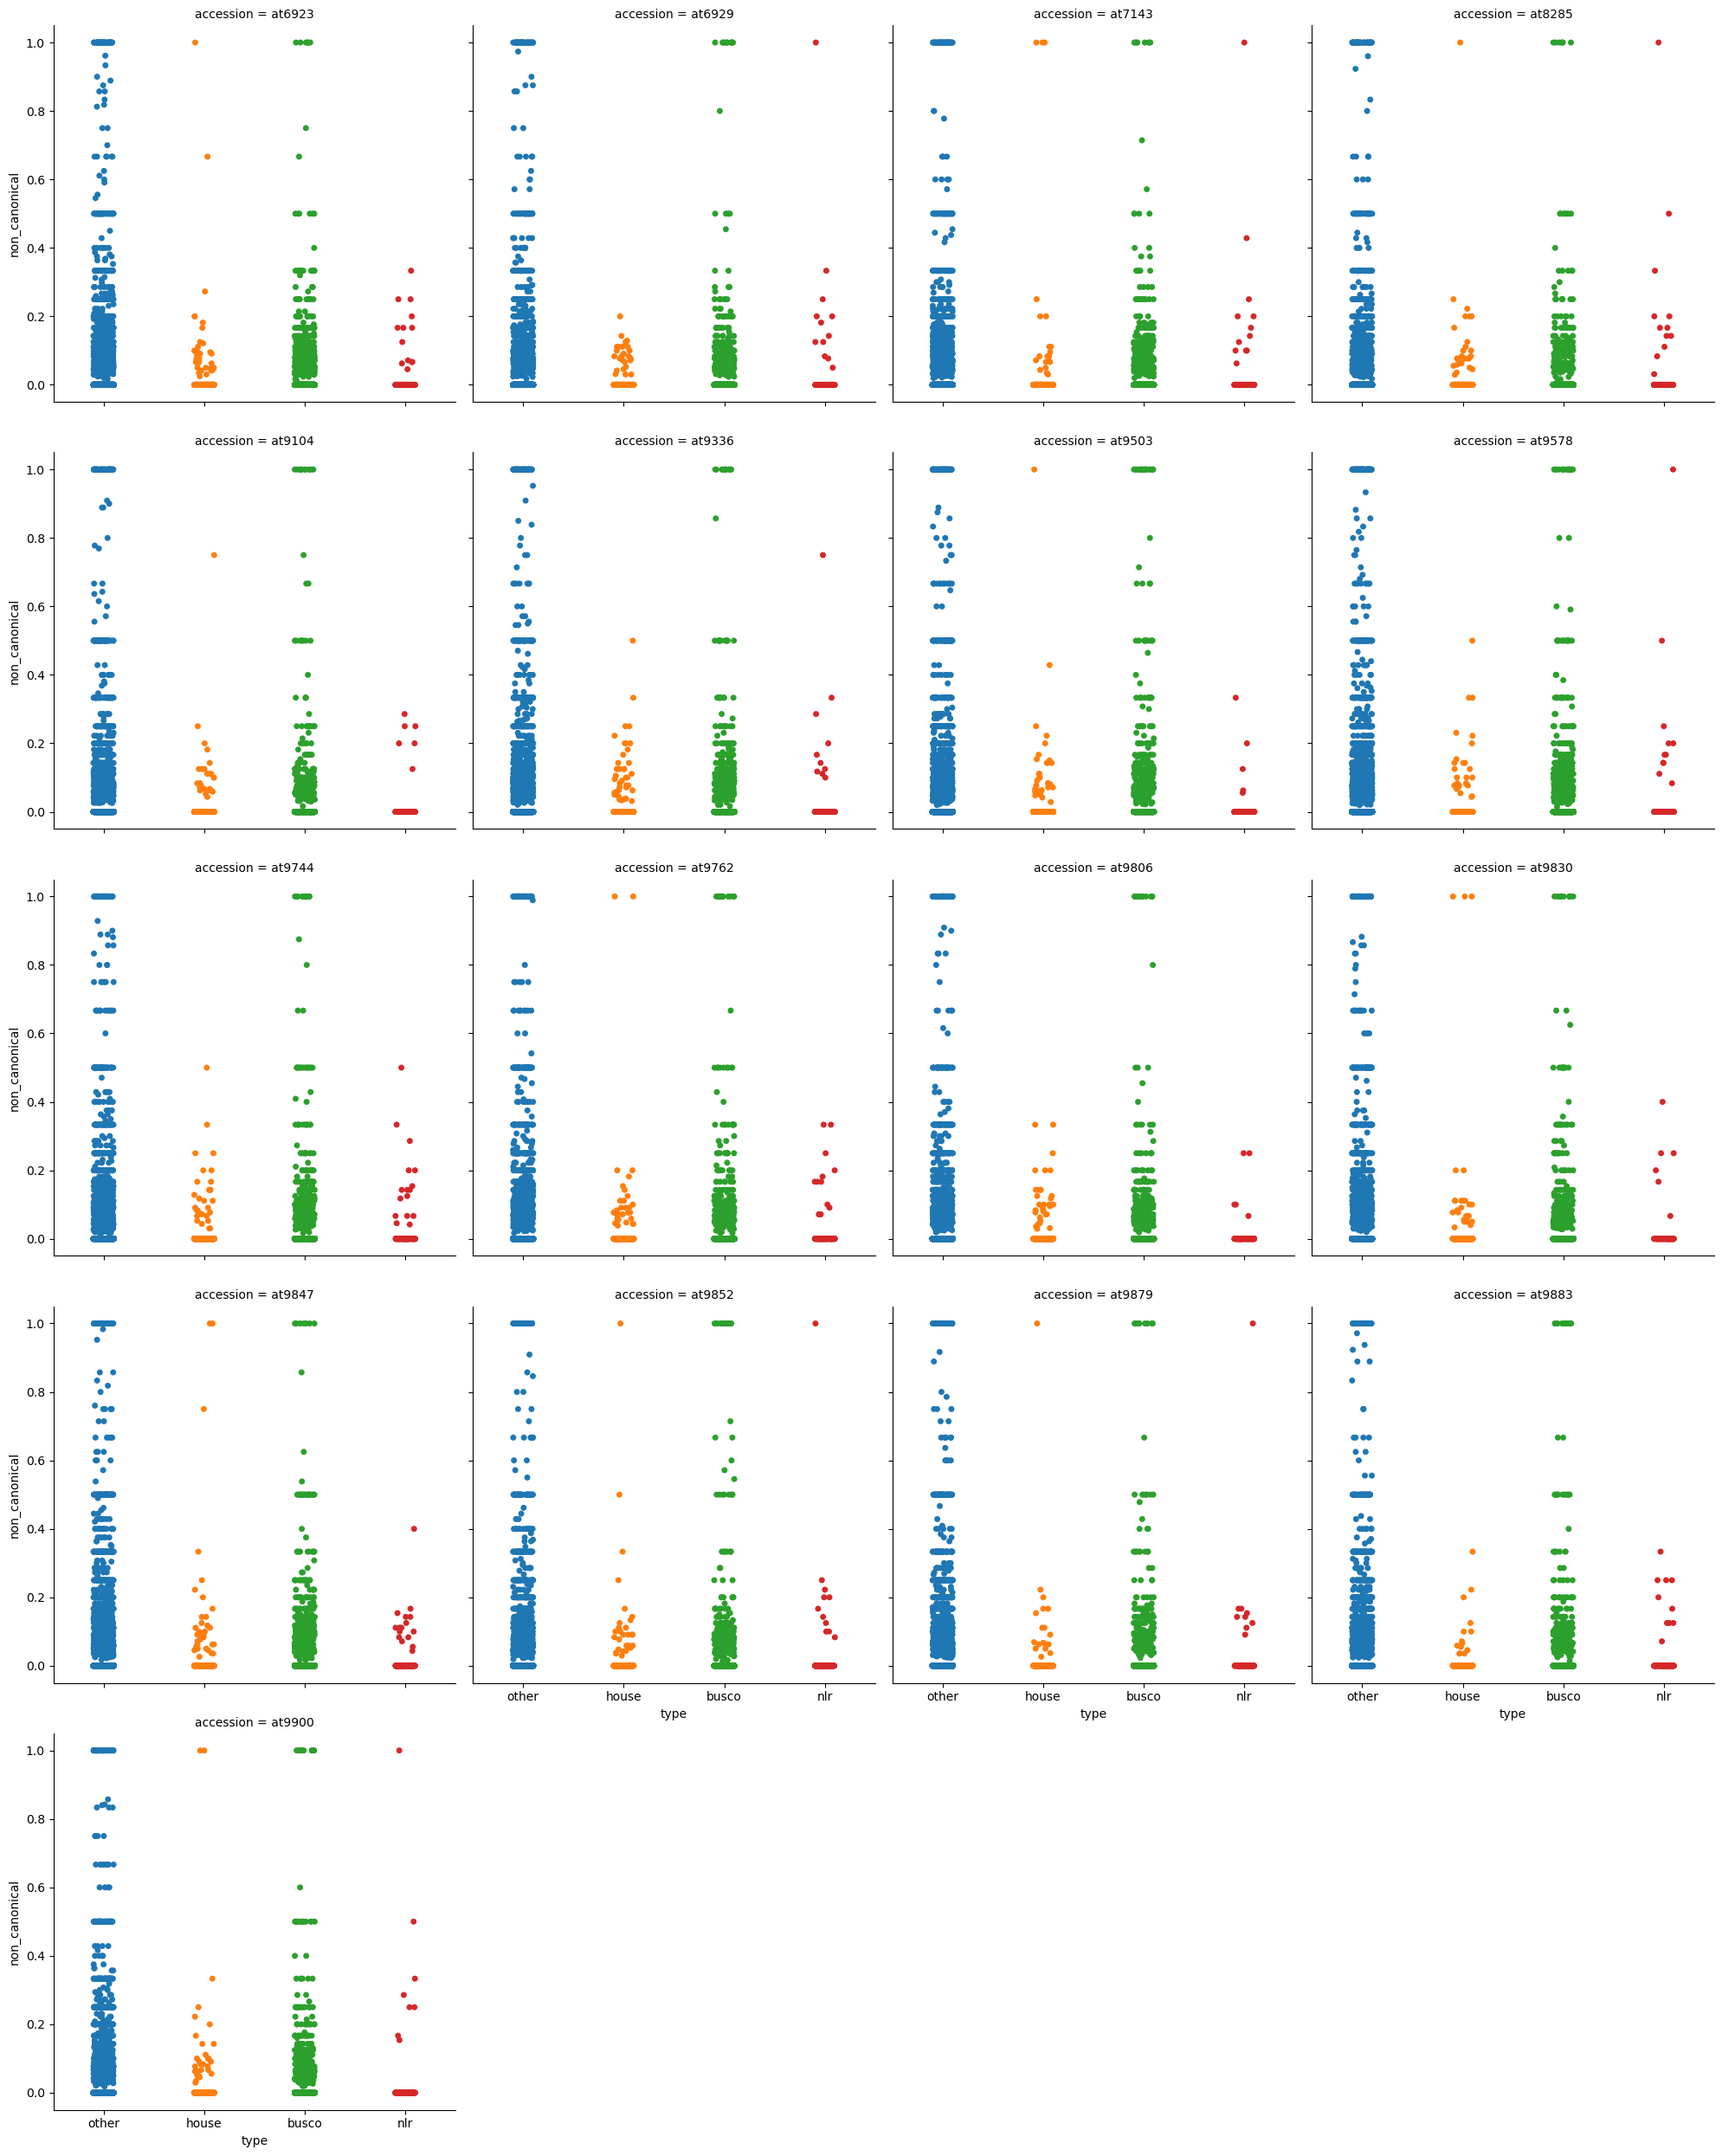

In [165]:
sns.catplot(canon_usage, x="type", y="non_canonical", hue="type", col="accession", col_wrap=4)

# Do statistis

In [167]:
from scipy.stats import mannwhitneyu
import numpy as np

In [171]:
refsets=["busco","house","other"]

stat_df=pd.DataFrame()
for acc in tqdm(accessions):
    for ref in refsets:

        nlr = canon_usage.loc[(canon_usage["type"]=="nlr")&(canon_usage["accession"]==acc)]
        other = canon_usage.loc[~(canon_usage["type"]==ref)&(canon_usage["accession"]==acc)]

        stat, p_value = mannwhitneyu(nlr["non_canonical"], other["non_canonical"])
        df=pd.DataFrame()
        df["acc"]=[acc]
        df["ref"]=ref
        df["p_value"]=p_value
        df["stat"]=stat
        stat_df=pd.concat([stat_df,df])

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:02<00:00,  6.06it/s]


In [172]:
stat_df

,acc,ref,p_value,stat
0,at6923,busco,0.696081,792609.5
0,at6923,house,0.685778,1004523.0
0,at6923,other,0.755268,273068.0
0,at6929,busco,0.263947,649545.0
0,at6929,house,0.251338,819973.5
0,at6929,other,0.227956,216936.5
0,at7143,busco,0.575202,740129.5
0,at7143,house,0.594242,937458.0
0,at7143,other,0.543175,253698.5
0,at8285,busco,0.298370,718199.0


## Get 